In [1]:
import mikeio
import modelskill as ms
import matplotlib.pyplot as plt 
import pandas as pd
import numpy as np

In [2]:
ms.options.metrics.list = ["urmse", "mae", "cc", "si", "r2"]

In [3]:
# mr_fldr = "../output_sample/"
mr_fldr = '../output/' # Change the output folder if needed  

fig_fldr = "../figures/"
save_png = False if "sample" in mr_fldr else True

mr_fn = "3D_2023_2025_hrly.dfsu" # model result file name

obs_fldr = "../observations/" 

In [4]:

time_start = pd.Timestamp("2025-12-28 00:00:00")
time_end = pd.Timestamp("2025-12-31 23:00:00")

In [5]:
ds = mikeio.read(f"{mr_fldr}{mr_fn}",items=[0,1,2],time = slice(time_start, time_end))
ds.items

[U velocity <u velocity component> (meter per sec),
 V velocity <v velocity component> (meter per sec),
 W velocity <w velocity component> (meter per sec)]

In [6]:
stations = pd.read_csv("../observations/stations_uv.csv")

Depth 4m not found in model for station LandskronaHamn


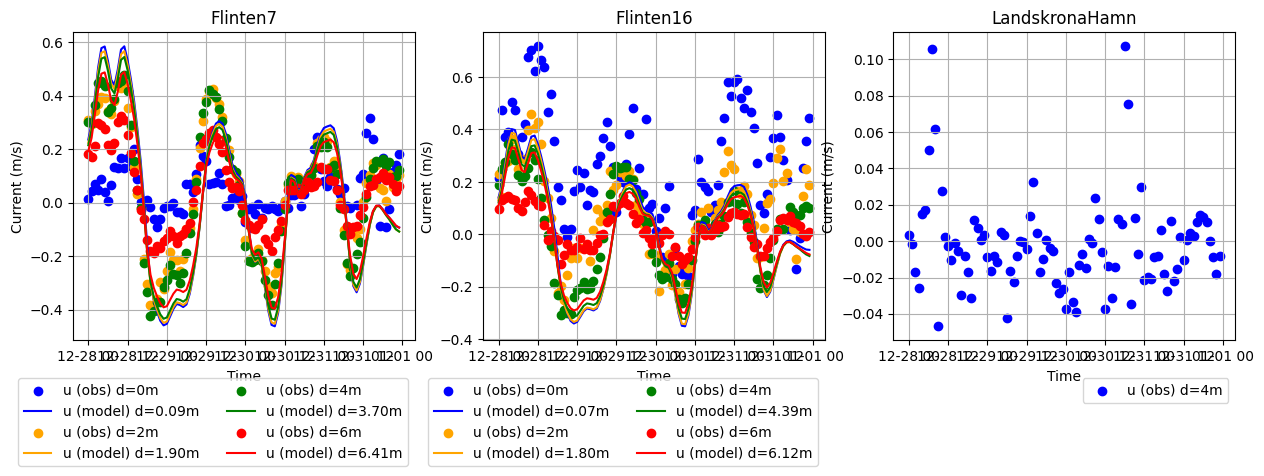

In [7]:
station_names = ["Flinten7", "Flinten16", "LandskronaHamn"]


# Pick 5 colors, one for each depth, and use them for both u and v
colors = ["blue", "orange", "green", "red", "purple"]

fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(15,4))

for i,station_name in enumerate(station_names):
    obs_data = pd.read_csv(f"{obs_fldr}{station_name}_u_v.csv",index_col=0, parse_dates=True).loc[time_start:time_end]
    st_info = stations[stations["Station"] == station_name]
    for j,d in enumerate(obs_data["depth"].unique()):
        obs_u = obs_data[obs_data["depth"]==d]["u"]
        # obs_v = obs_data[obs_data["depth"]==d]["v"]
        axs[i].scatter(obs_u.index, obs_u.values, label=f"u (obs) d={d}m", color=colors[j], marker="o")
        # axs[i].plot(obs_v.index, obs_v.values, label=f"v (obs) depth={d}m", color=colors[j], linestyle="dotted")
        try:
            model_u = ds[0].sel(time=slice(time_start, time_end),x=st_info['Longitude'],y=st_info['Latitude'],z=-d)
        except ValueError:
            print(f"Depth {d}m not found in model for station {station_name}")
            continue
        axs[i].plot(model_u.time, model_u.values, label=f"u (model) d={-model_u.geometry.z:.2f}m", color=colors[j])
    axs[i].set_title(station_name)
    axs[i].set_xlabel("Time")
    axs[i].set_ylabel("Current (m/s)")
    axs[i].legend(ncol=2,bbox_to_anchor=(1, -0.1))
    axs[i].grid()

In [8]:
obs_u

datetime_UTC
2025-12-28 00:00:00    0.0035
2025-12-28 01:00:00   -0.0014
2025-12-28 02:00:00   -0.0169
2025-12-28 03:00:00   -0.0258
2025-12-28 04:00:00    0.0148
                        ...  
2025-12-31 19:00:00    0.0107
2025-12-31 20:00:00    0.0000
2025-12-31 21:00:00   -0.0088
2025-12-31 22:00:00   -0.0178
2025-12-31 23:00:00   -0.0084
Name: u, Length: 96, dtype: float64

In [9]:
st_info

,Station,Longitude,Latitude,Longitude_original,Latitude_original
2,LandskronaHamn,12.819,55.855,12.8293,55.8594


In [10]:
ds[0].sel(time=slice(time_start, time_end),x=st_info['Longitude'],y=st_info['Latitude']).geometry.element_coordinates


array([[12.81559614, 55.85192578, -2.34020302],
       [12.81559614, 55.85192578, -2.05597111],
       [12.81559614, 55.85192578, -1.77173921],
       [12.81559614, 55.85192578, -1.48750731],
       [12.81559614, 55.85192578, -1.20327544],
       [12.81559614, 55.85192578, -0.91904353],
       [12.81559614, 55.85192578, -0.63481165],
       [12.81559614, 55.85192578, -0.35057976],
       [12.81559614, 55.85192578, -0.06634785],
       [12.81559614, 55.85192578,  0.21788406]])

In [11]:
ds[0].sel(time=slice(time_start, time_end),x=st_info['Longitude'],y=st_info['Latitude']).geometry.element_coordinates[:,-1]

array([-2.34020302, -2.05597111, -1.77173921, -1.48750731, -1.20327544,
       -0.91904353, -0.63481165, -0.35057976, -0.06634785,  0.21788406])

No observation data for u at depth 0m for station LandskronaHamn
No observation data for u at depth 2m for station LandskronaHamn
Depth 4m not found in model for station LandskronaHamn
No observation data for u at depth 6m for station LandskronaHamn


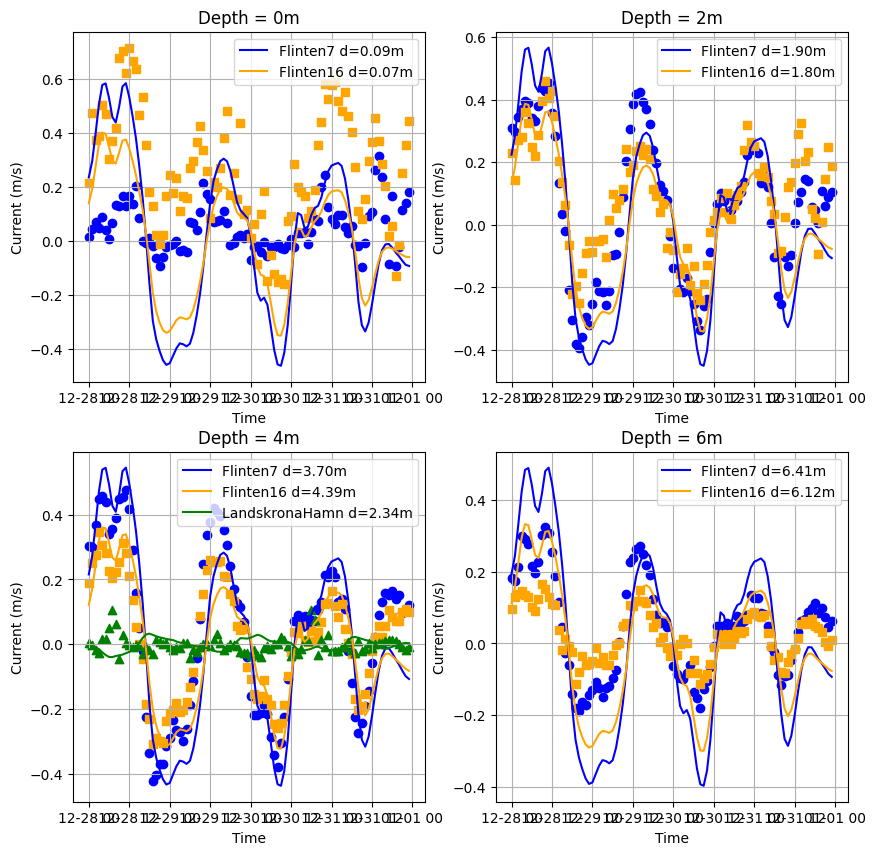

In [12]:
station_names = ["Flinten7", "Flinten16", "LandskronaHamn"]
depths = [0,2,4,6]

# Pick 3 colors, one for each station
colors = ["blue", "orange", "green"]
# Pick three markers, one for each station
markers = ["o", "s", "^"]

fig, axs = plt.subplots(nrows=2, ncols=2, figsize=(10,10))

axes = axs.flatten()

for i,d in enumerate(depths):
    for j,station_name in enumerate(station_names):
        obs_data = pd.read_csv(f"{obs_fldr}{station_name}_u_v.csv",index_col=0, parse_dates=True).loc[time_start:time_end]
        st_info = stations[stations["Station"] == station_name]
        obs_u = obs_data[obs_data["depth"]==d]["u"]
        if obs_u.empty:
            print(f"No observation data for u at depth {d}m for station {station_name}")
            continue
        # obs_v = obs_data[obs_data["depth"]==d]["v"]
        axes[i].scatter(obs_u.index, obs_u.values, label=None, color=colors[j], marker=markers[j])
        # axes[i].plot(obs_v.index, obs_v.values, label=f"v (obs) depth={d}m", color=colors[j], linestyle="dotted")
        try:
            model_u = ds[0].sel(time=slice(time_start, time_end),x=st_info['Longitude'],y=st_info['Latitude'],z=-d)
        except ValueError:
            print(f"Depth {d}m not found in model for station {station_name}")
            max_depth_model = ds[0].sel(time=slice(time_start, time_end),x=st_info['Longitude'],y=st_info['Latitude']).geometry.element_coordinates[:,-1].min()
            model_u = ds[0].sel(time=slice(time_start, time_end),x=st_info['Longitude'],y=st_info['Latitude'],z=max_depth_model)
        axes[i].plot(model_u.time, model_u.values, label=f"{station_name} d={-model_u.geometry.z:.2f}m", color=colors[j])

        axes[i].legend()
    axes[i].set_title("Depth = {}m".format(d))
    axes[i].set_xlabel("Time")
    axes[i].set_ylabel("Current (m/s)")
    
    axes[i].grid()


